# C3 Vision Oracle: live demo

Each screen below is analysed **live** by the shipped model, through the same service the HEART app's *Inspect screenshot* button uses (global view, retrained adapter `c3_v3_vision_1ep`, decision threshold 0.30 read from the adapter's own contract). All nine screens are in the held-out test split of the retrained dataset, so the model never trained on them.

**Red box** = the region the model flagged (approximate). **Green box** = where the defect really is.

These are selected screens that show behaviour. For accuracy, quote the held-out test only: AUC 0.81, F1 0.78, precision 68%, recall 90% on 425 screens. At this threshold about half of clean screens are also flagged, so a clean screen shown as flagged below is expected behaviour, not a surprise.

Run the cells from top to bottom. The first cell loads the model (about 20–40 s). Each screen then takes about 1 s if clean, or 8–10 s if a defect is found.

In [2]:
import sys, time
from pathlib import Path
C3 = next(p for p in [Path.cwd().resolve(), *Path.cwd().resolve().parents] if (p / 'demo_inputs').exists())
sys.path.insert(0, str(C3.parent))
import os, json
os.environ['C3_ADAPTER'] = str(C3 / 'models' / 'c3_v3_vision_1ep')   # the retrained adapter
THRESH = json.loads((Path(os.environ['C3_ADAPTER']) / 'inference_contract.json').read_text(encoding='utf-8'))['decision_threshold']
import vision_oracle.services.oracle_service as svc_mod   # must be imported first (path guard)
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from PIL import Image

t = time.perf_counter()
service = svc_mod.get_oracle_service()
print(f'Model loaded in {time.perf_counter() - t:.0f} s')
DEMO = C3 / 'demo_inputs'

# Expected answers and true defect regions [ymin, xmin, ymax, xmax] in 0-1000 (relabelled by eye).
EXPECTED = {
    '01_overlap_team_names.jpg': ('component_overlap', [200, 0, 340, 1000]),
    '02_overlap_title.jpg': ('component_overlap', [240, 150, 300, 560]),
    '03_null_text.jpg': ('data_binding_null', [262, 450, 295, 560]),
    '04_missing_icons.jpg': ('missing_component', [294, 80, 380, 250]),
    '05_missing_widget_synthetic.jpg': ('missing_component', None),
    '06_overlap_synthetic.jpg': ('component_overlap', None),
    '07_clean_owleye.jpg': ('none', None),
    '08_clean_rico.jpg': ('none', None),
    '09_known_miss_truncation.jpg': ('text_truncation', [190, 0, 215, 350]),
}

def inspect(name, layout=None):
    path = DEMO / name
    hierarchy = (DEMO / layout).read_text(encoding='utf-8') if layout else None
    t = time.perf_counter()
    res = service.evaluate(image_input=str(path), raw_hierarchy=hierarchy, session_id='notebook_demo', enable_sahi=False)
    secs = time.perf_counter() - t
    v = res['verdict_v2']
    decision = getattr(v['decision'], 'value', v['decision'])
    f = v['findings'][0] if v['findings'] else {}
    got = f.get('type', 'none')
    expected, gold = EXPECTED[name]
    img = Image.open(path).convert('RGB'); W, H = img.size
    fig, ax = plt.subplots(figsize=(4.5, 8)); ax.imshow(img); ax.axis('off')
    if gold:
        y1, x1, y2, x2 = gold
        ax.add_patch(Rectangle((x1*W/1000, y1*H/1000), (x2-x1)*W/1000, (y2-y1)*H/1000, fill=False, ec='lime', lw=3))
    if f.get('bbox_xyxy'):
        x1, y1, x2, y2 = f['bbox_xyxy']
        ax.add_patch(Rectangle((x1, y1), x2-x1, y2-y1, fill=False, ec='red', lw=3))
    ok = got == expected
    ax.set_title(('CORRECT' if ok else 'MISSED') + f'\nexpected {expected}\nmodel {got}', color='green' if ok else 'red', fontsize=10)
    plt.show()
    score = v['metadata'].get('defect_probability')
    print(f"Decision : {decision}")
    print(f"Type     : model said '{got}', expected '{expected}' -> {'CORRECT' if ok else 'MISSED'}")
    print(f"Score    : {score:.2f} (flagged at {THRESH:.2f} or above)" if score is not None else 'Score: -')
    if f.get('element_ref'):
        print(f"Element  : {f['element_ref']} (matched from the layout file)")
    print(f"Time     : {secs:.1f} s")

Model loaded in 0 s


## 1. Real bug: overlapping text

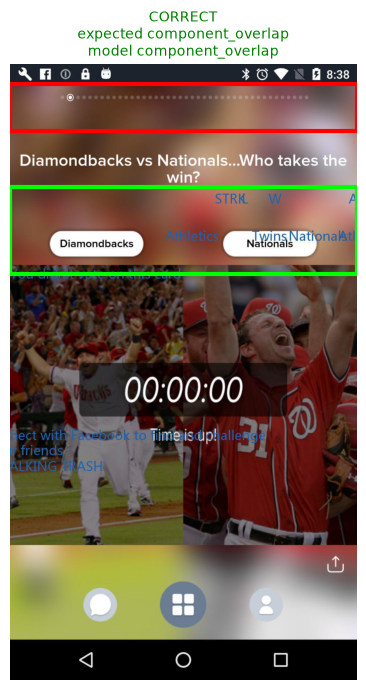

Decision : defect_detected
Type     : model said 'component_overlap', expected 'component_overlap' -> CORRECT
Score    : 0.38 (flagged at 0.30 or above)
Time     : 9.8 s


In [2]:
inspect('01_overlap_team_names.jpg')

## 2. Real bug: title drawn over the description

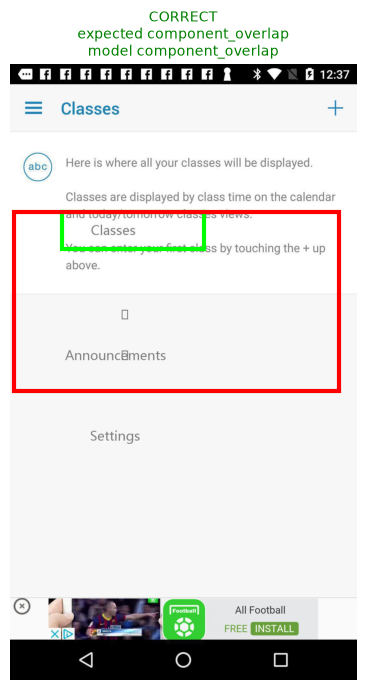

Decision : defect_detected
Type     : model said 'component_overlap', expected 'component_overlap' -> CORRECT
Score    : 0.67 (flagged at 0.30 or above)
Time     : 20.3 s


In [3]:
inspect('02_overlap_title.jpg')

## 3. Real bug: the word 'null' shown to the user

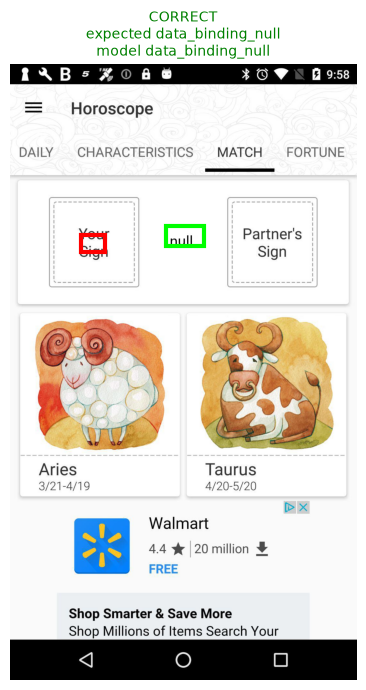

Decision : defect_detected
Type     : model said 'data_binding_null', expected 'data_binding_null' -> CORRECT
Score    : 1.00 (flagged at 0.30 or above)
Time     : 7.6 s


In [4]:
inspect('03_null_text.jpg')

## 4. Real bug: icons not rendered

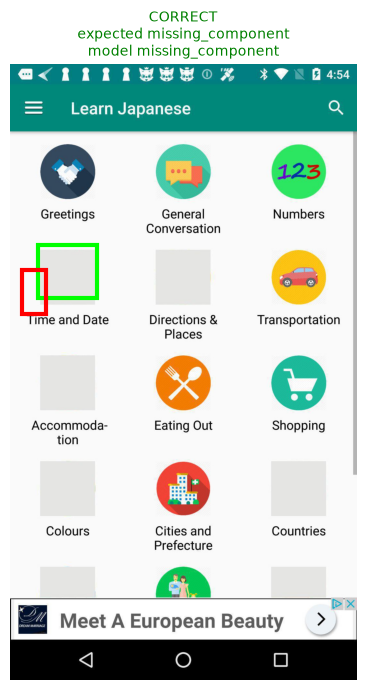

Decision : defect_detected
Type     : model said 'missing_component', expected 'missing_component' -> CORRECT
Score    : 0.64 (flagged at 0.30 or above)
Time     : 7.0 s


In [5]:
inspect('04_missing_icons.jpg')

## 5. Synthetic bug: grey placeholder replaces a widget

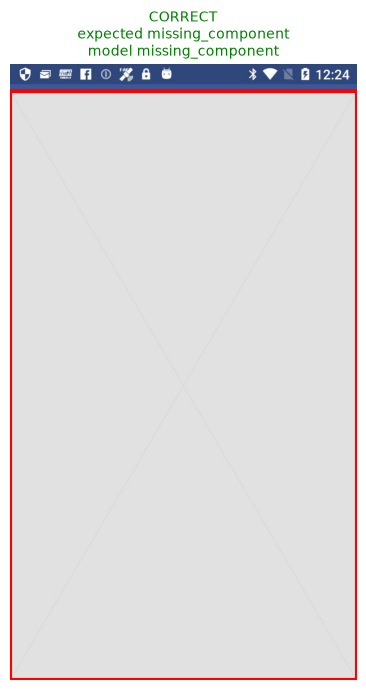

Decision : defect_detected
Type     : model said 'missing_component', expected 'missing_component' -> CORRECT
Score    : 0.92 (flagged at 0.30 or above)
Time     : 10.3 s


In [4]:
inspect('05_missing_widget_synthetic.jpg')

## 6. Synthetic bug with layout file: the result names the real element

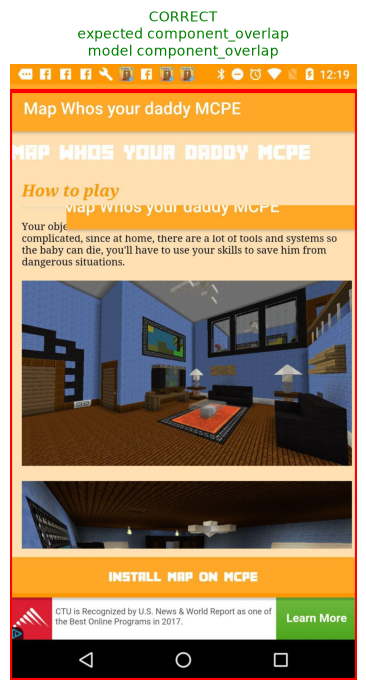

Decision : defect_detected
Type     : model said 'component_overlap', expected 'component_overlap' -> CORRECT
Score    : 0.64 (flagged at 0.30 or above)
Element  : com.mevikings.mapwhosyourdaddy:id/wbdesc (matched from the layout file)
Time     : 10.7 s


In [6]:
inspect('06_overlap_synthetic.jpg', layout='06_overlap_synthetic_layout.json')

## 7. Clean screen: should not be flagged

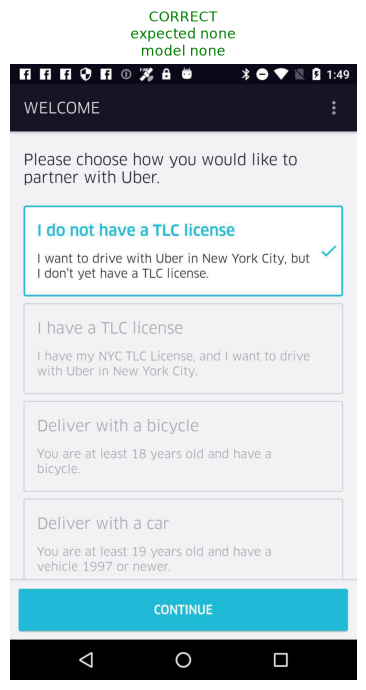

Decision : no_defect_detected
Type     : model said 'none', expected 'none' -> CORRECT
Score    : 0.36 (flagged at 0.30 or above)
Time     : 2.1 s


In [7]:
inspect('07_clean_owleye.jpg')

## 8. Clean screen: should not be flagged

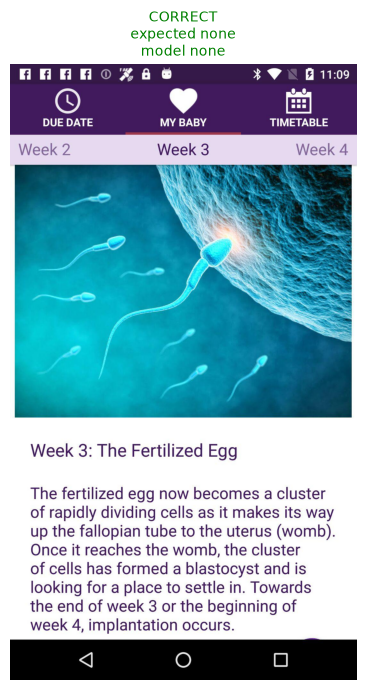

Decision : no_defect_detected
Type     : model said 'none', expected 'none' -> CORRECT
Score    : 0.36 (flagged at 0.30 or above)
Time     : 1.2 s


In [8]:
inspect('08_clean_rico.jpg')

## 9. Known limitation: thin clipped text is missed

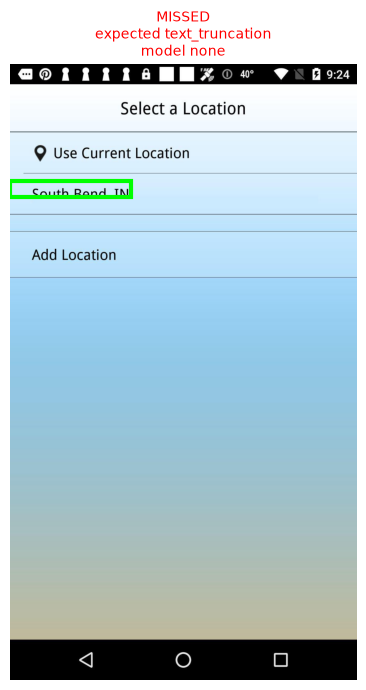

Decision : no_defect_detected
Type     : model said 'none', expected 'text_truncation' -> MISSED
Score    : 0.53 (flagged at 0.30 or above)
Time     : 1.1 s


In [9]:
inspect('09_known_miss_truncation.jpg')

## Try your own screenshot
Put any screenshot path below and run the cell (expected answer unknown, so no green box).

In [11]:
MY_SCREEN = r''   # e.g. r'C:\\Users\\you\\Desktop\\screen.png'
if MY_SCREEN:
    r = service.evaluate(image_input=MY_SCREEN, session_id='notebook_demo', enable_sahi=False)['verdict_v2']
    img = Image.open(MY_SCREEN).convert('RGB'); fig, ax = plt.subplots(figsize=(4.5, 8)); ax.imshow(img); ax.axis('off')
    for f in r['findings']:
        x1, y1, x2, y2 = f['bbox_xyxy']; ax.add_patch(Rectangle((x1, y1), x2-x1, y2-y1, fill=False, ec='red', lw=3))
    ax.set_title(f"{getattr(r['decision'], 'value', r['decision'])}: {[f['type'] for f in r['findings']]}"); plt.show()
    print('score', r['metadata'].get('defect_probability'))